In [4]:
import pandas as pd 
import numpy as np

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

from xgboost import XGBRegressor


import pickle

In [5]:
df=pd.read_csv("demand_forecasting.csv")

In [6]:
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84


In [7]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='object')

In [8]:
features=["Price",
"Discount",
"Inventory Level",
"Promotion",
"Competitor Pricing",
"Category"
]

In [9]:
features

['Price',
 'Discount',
 'Inventory Level',
 'Promotion',
 'Competitor Pricing',
 'Category']

In [13]:
target="Demand"

In [10]:
x=df[features].copy()

In [11]:
x

,Price,Discount,Inventory Level,Promotion,Competitor Pricing,Category
0,72.72,5,195,0,85.73,Electronics
1,80.16,15,117,1,92.02,Clothing
2,62.94,10,247,1,60.08,Clothing
3,87.63,10,139,0,85.19,Electronics
4,54.41,0,152,0,51.63,Groceries
...,...,...,...,...,...,...
75995,29.80,5,233,0,32.23,Toys
75996,42.92,5,137,0,40.73,Toys
75997,17.81,10,197,0,19.41,Clothing
75998,151.72,0,125,0,143.71,Furniture


In [14]:
y=df[target]


In [15]:
y

0        115
1        229
2        157
3         52
4         59
        ... 
75995     64
75996    137
75997     68
75998     84
75999     73
Name: Demand, Length: 76000, dtype: int64

In [16]:
from dask.dataframe import categorical
label_encoders={}

categorical_cols=x.select_dtypes(include=object).columns

In [17]:
categorical_cols

Index(['Category'], dtype='object')

In [18]:
for col in categorical_cols:
    le=LabelEncoder()
    x[col]=le.fit_transform(x[col])
    label_encoders[col]=le

In [19]:
label_encoders

{'Category': LabelEncoder()}

## Model Training

In [20]:

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42 )

In [21]:
x

,Price,Discount,Inventory Level,Promotion,Competitor Pricing,Category
0,72.72,5,195,0,85.73,1
1,80.16,15,117,1,92.02,0
2,62.94,10,247,1,60.08,0
3,87.63,10,139,0,85.19,1
4,54.41,0,152,0,51.63,3
...,...,...,...,...,...,...
75995,29.80,5,233,0,32.23,4
75996,42.92,5,137,0,40.73,4
75997,17.81,10,197,0,19.41,0
75998,151.72,0,125,0,143.71,2


In [27]:
xgb = XGBRegressor(objective="reg:squarederror", n_jobs=-1)

In [28]:
param_dict={
    "n_estimators":[200,300,500],
    "max_depth":[3,4,6,8],
    "learning_rate":[0.01,0.05,0.1],
    "subsample":[0.7,0.8,1.0],
    "colsample_bytree":[0.7,0.8,1.0],
    "min_child_weight":[1,3,5]

}

In [29]:
random_search=RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dict,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=1,
    n_jobs=-1
)

In [30]:
random_search.fit(x_train,y_train)

Fitting 3 folds for each of 25 candidates, totalling 75 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,n_iter,25
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [31]:
random_search.best_params_

{'subsample': 0.8,
 'n_estimators': 500,
 'min_child_weight': 3,
 'max_depth': 6,
 'learning_rate': 0.05,
 'colsample_bytree': 1.0}

In [32]:
best_model=random_search.best_estimator_

In [33]:
best_model.predict(x_test)

array([ 80.542114,  69.83648 ,  38.0097  , ...,  73.06569 ,  59.1754  ,
       108.33523 ], shape=(15200,), dtype=float32)

In [34]:
y_pred=best_model.predict(x_test)

In [37]:
from sklearn.metrics import root_mean_squared_error

root_mean_squared_error(y_test, y_pred)

35.5623893737793

In [38]:
best_model.feature_importances_

array([0.09011611, 0.02762041, 0.02296544, 0.58109033, 0.03286359,
       0.24534412], dtype=float32)

In [39]:
feature_importance=pd.Series(
    best_model.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

In [40]:
feature_importance

Promotion             0.581090
Category              0.245344
Price                 0.090116
Competitor Pricing    0.032864
Discount              0.027620
Inventory Level       0.022965
dtype: float32

<Axes: title={'center': 'Feature Importances'}>

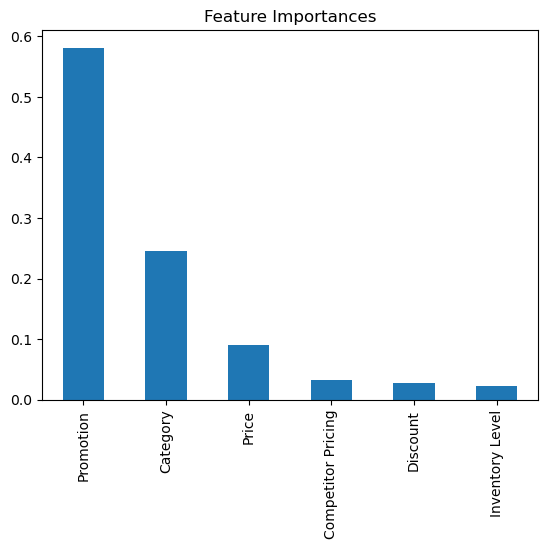

In [42]:
feature_importance.plot(kind="bar",title="Feature Importances")

In [43]:
with open("label_encoders.pkl","wb") as f:
    pickle.dump(label_encoders, f)

In [44]:
with open("xgboost_demand_model.pkl","wb") as f:
    pickle.dump(best_model,f)